# CogniStream — Statistical Analysis

## Objectives
1. Compare cognitive load across task outcomes.
2. Quantify group differences using effect sizes.
3. Investigate associations between work variables and cognitive load.
4. Investigate associations between work variables and task success.
5. Adjust for multiple comparisons.
6. Export reproducible statistical results.

## Interpretation
Statistical association does not establish causation.
The dataset is observational and does not establish actual flow-state duration.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "src" / "schema.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate CogniStream project root."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis import (
    validate_analysis_data,
    summarize_by_success,
    compare_cognitive_load,
    feature_associations,
    run_analysis,
    FEATURED_DATA_PATH,
)

print("CogniStream statistical analysis initialized.")
print("Project root:", PROJECT_ROOT)

CogniStream statistical analysis initialized.
Project root: C:\PlayGround\Infotact Data Analytics\CogniStream


In [2]:
if not FEATURED_DATA_PATH.exists():
    raise FileNotFoundError(
        "Featured dataset not found. Complete Steps 3 and 4 first."
    )

df = pd.read_csv(FEATURED_DATA_PATH)

validate_analysis_data(df)

print("Dataset shape:", df.shape)
print("Task success counts:")
display(df["task_success"].value_counts().sort_index())

display(df.head())

Dataset shape: (500, 18)
Task success counts:


task_success
0.0    197
1.0    303
Name: count, dtype: int64

,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success,coding_hours_band,sleep_band,cognitive_load_band,distraction_band,distractions_per_coding_hour,commits_per_coding_hour,bugs_per_commit,ai_hours_per_coding_hour,task_success_label
0,5.99,600.0,1.0,5.8,2.0,1.0,0.71,5.4,1.0,Moderate (>4-8h),Short (<6h),Moderate (>3-6),Low (0-2),0.166945,0.333890,0.500000,0.118531,Successful
1,4.72,568.0,2.0,6.9,5.0,3.0,1.75,4.7,1.0,Moderate (>4-8h),Medium (6-<8h),Moderate (>3-6),Low (0-2),0.423729,1.059322,0.600000,0.370763,Successful
2,6.30,560.0,1.0,8.9,2.0,0.0,2.27,2.2,1.0,Moderate (>4-8h),Long (>=8h),Low (<=3),Low (0-2),0.158730,0.317460,0.000000,0.360317,Successful
3,8.05,600.0,7.0,6.3,9.0,5.0,1.40,5.9,0.0,Long (>8h),Medium (6-<8h),Moderate (>3-6),High (6+),0.869565,1.118012,0.555556,0.173913,Unsuccessful
4,4.53,421.0,6.0,6.9,4.0,0.0,1.26,6.3,1.0,Moderate (>4-8h),Medium (6-<8h),High (>6),High (6+),1.324503,0.883002,0.000000,0.278146,Successful


In [3]:
group_summary = summarize_by_success(df)

display(group_summary)

,task_outcome,observations,mean,median,standard_deviation,minimum,maximum
0,Successful,303,4.197,4.4,1.568,1.0,6.9
1,Unsuccessful,197,4.961,4.7,2.179,1.0,10.0


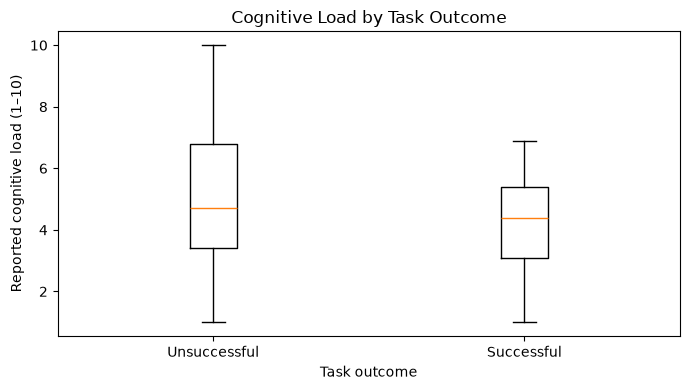

In [4]:
groups = [
    df.loc[
        df["task_success"] == outcome,
        "cognitive_load",
    ].dropna()
    for outcome in [0, 1]
]

fig, ax = plt.subplots(figsize=(7, 4))

ax.boxplot(groups)

ax.set_xticks(
    [1, 2],
    labels=["Unsuccessful", "Successful"],
)

ax.set_title("Cognitive Load by Task Outcome")
ax.set_ylabel("Reported cognitive load (1–10)")
ax.set_xlabel("Task outcome")

fig.tight_layout()
plt.show()

In [5]:
test_result = compare_cognitive_load(df)

print("=" * 55)
print("COGNITIVE LOAD GROUP COMPARISON")
print("=" * 55)

for metric, value in test_result.items():
    print(f"{metric}: {value}")

COGNITIVE LOAD GROUP COMPARISON
test: Mann–Whitney U
successful_n: 303
unsuccessful_n: 197
successful_mean: 4.197359735973597
unsuccessful_mean: 4.960913705583756
successful_median: 4.4
unsuccessful_median: 4.7
median_difference_success_minus_unsuccessful: -0.2999999999999998
u_statistic: 24254.0
p_value: 0.00039668571747036424
rank_biserial_effect_size: -0.18734817644200963


In [6]:
association_results = feature_associations(df)

display(
    association_results[
        [
            "feature",
            "target",
            "method",
            "n",
            "correlation",
            "p_value",
            "adjusted_p_value",
            "significant_at_0_05_fdr",
        ]
    ].round(4)
)

,feature,target,method,n,correlation,p_value,adjusted_p_value,significant_at_0_05_fdr
0,sleep_hours,cognitive_load,Spearman,500,-0.7127,0.0000,0.0000,True
1,distractions,cognitive_load,Spearman,500,0.4172,0.0000,0.0000,True
2,bugs_reported,cognitive_load,Spearman,500,0.2810,0.0000,0.0000,True
3,ai_usage_hours,cognitive_load,Spearman,500,0.1177,0.0084,0.0147,True
4,coffee_intake_mg,cognitive_load,Spearman,500,0.0685,0.1263,0.1644,False
5,commits,cognitive_load,Spearman,500,0.0659,0.1409,0.1644,False
6,hours_coding,cognitive_load,Spearman,500,0.0588,0.1893,0.1893,False
7,coffee_intake_mg,task_success,Point-biserial,500,0.6952,0.0000,0.0000,True
8,hours_coding,task_success,Point-biserial,500,0.6155,0.0000,0.0000,True
9,commits,task_success,Point-biserial,500,0.3389,0.0000,0.0000,True


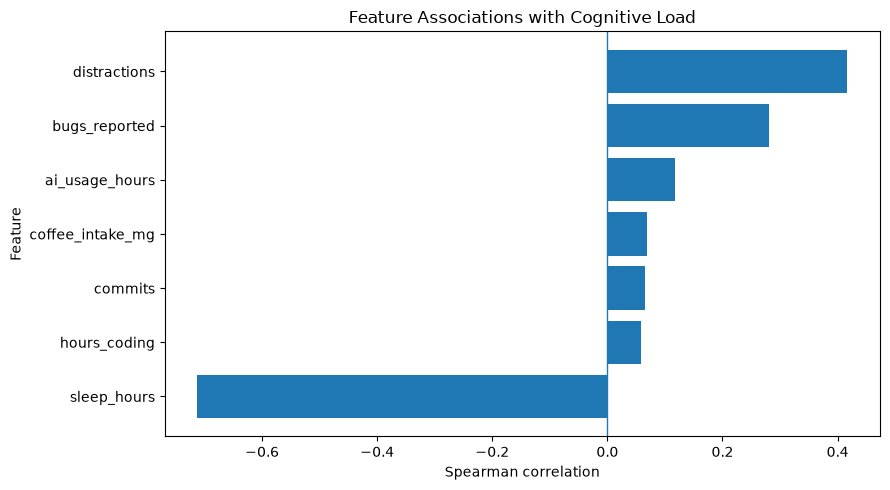

In [7]:
load_results = association_results.loc[
    association_results["target"] == "cognitive_load"
].dropna(subset=["correlation"])

load_results = load_results.sort_values(
    "correlation",
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    load_results["feature"],
    load_results["correlation"],
)

ax.axvline(
    0,
    linewidth=1,
)

ax.set_title("Feature Associations with Cognitive Load")
ax.set_xlabel("Spearman correlation")
ax.set_ylabel("Feature")

fig.tight_layout()
plt.show()

In [8]:
summary_results, group_test_results, association_results = (
    run_analysis(FEATURED_DATA_PATH)
)

print("\nAll statistical reports generated.")

COGNISTREAM — STATISTICAL ANALYSIS

Cognitive load by outcome:
task_outcome  observations  mean  median  standard_deviation  minimum  maximum
  Successful           303 4.197     4.4               1.568      1.0      6.9
Unsuccessful           197 4.961     4.7               2.179      1.0     10.0

Mann–Whitney U test:
test: Mann–Whitney U
successful_n: 303
unsuccessful_n: 197
successful_mean: 4.197359735973597
unsuccessful_mean: 4.960913705583756
successful_median: 4.4
unsuccessful_median: 4.7
median_difference_success_minus_unsuccessful: -0.2999999999999998
u_statistic: 24254.0
p_value: 0.00039668571747036424
rank_biserial_effect_size: -0.18734817644200963

Feature associations:
         feature         target         method   n  correlation      p_value  adjusted_p_value  significant_at_0_05_fdr
     sleep_hours cognitive_load       Spearman 500    -0.712666 1.052603e-78      7.368221e-78                     True
    distractions cognitive_load       Spearman 500     0.417178 1.785

In [9]:
p_value = test_result["p_value"]
effect_size = test_result["rank_biserial_effect_size"]

print("INTERPRETATION")

if p_value is None:
    print("Insufficient observations to perform the group comparison.")

elif p_value < 0.05:
    print(
        "The group comparison provides statistical evidence "
        "of a difference in cognitive-load distributions."
    )
    print(
        "Report the group medians, effect size, and p-value "
        "together. Do not infer causation."
    )

else:
    print(
        "The group comparison did not provide sufficient "
        "evidence of a difference at the 0.05 significance level."
    )
    print(
        "This does not establish that the groups are equivalent."
    )

print("\nRank-biserial effect size:", effect_size)
print("\nAnalysis completed.")

INTERPRETATION
The group comparison provides statistical evidence of a difference in cognitive-load distributions.
Report the group medians, effect size, and p-value together. Do not infer causation.

Rank-biserial effect size: -0.18734817644200963

Analysis completed.
